# **Coding Tests**

## **Get Insights From Data**

### **Libraries Setup**

In [1]:
from pathlib import Path

import pandas as pd
import plotly.graph_objects as go
from IPython.display import Markdown, display
from plotly.colors import qualitative
from plotly.subplots import make_subplots

### **Constants**

In [2]:
# Plotly Config
TEMPLATE = "plotly_white"
COLOR = "#3b6ea8"
YEAR_COLORS = {2020: "#3b6ea8", 2021: "#e08a3c", 2022: "#5aa469"}


# Days Config
WEEKDAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]


# Region Config
MERGED_NAMES = {
    "Congo": "Republic of the Congo and DR Congo",
    "Korea": "North and South Korea",
}

REGIONS = {
    "North America": [
        "United States of America", "Canada", "Greenland", "Bermuda",
        "Saint Pierre and Miquelon",
    ],
    "Central America": [
        "Mexico", "Guatemala", "Belize", "Honduras", "El Salvador",
        "Nicaragua", "Costa Rica", "Panama",
    ],
    "Caribbean": [
        "Anguilla", "Antigua and Barbuda", "Aruba", "Bahamas", "Barbados",
        "British Virgin Islands", "Cayman Islands", "Cuba", "Dominica",
        "Dominican Republic", "Grenada", "Guadeloupe", "Haiti", "Jamaica",
        "Martinique", "Montserrat", "Netherlands Antilles", "Puerto Rico",
        "Saint Barthelemy", "Saint Kitts and Nevis", "Saint Lucia",
        "Saint Martin", "Saint Vincent and the Grenadines",
        "Trinidad and Tobago", "Turks and Caicos Islands",
        "United States Virgin Islands",
    ],
    "South America": [
        "Argentina", "Bolivia", "Brazil", "Chile", "Colombia", "Ecuador",
        "Falkland Islands (Malvinas)", "French Guiana", "Guyana", "Paraguay",
        "Peru", "Suriname", "Uruguay", "Venezuela",
    ],
    "Europe": [
        "Albania", "Andorra", "Austria", "Belarus", "Belgium",
        "Bosnia and Herzegovina", "Bulgaria", "Croatia", "Cyprus",
        "Czech Republic", "Denmark", "Estonia", "Faroe Islands", "Finland",
        "France", "Germany", "Gibraltar", "Greece", "Guernsey",
        "Holy See (Vatican City State)", "Hungary", "Iceland", "Ireland",
        "Isle of Man", "Italy", "Jersey", "Latvia", "Liechtenstein",
        "Lithuania", "Luxembourg", "Macedonia", "Malta", "Moldova", "Monaco",
        "Montenegro", "Netherlands", "Norway", "Poland", "Portugal",
        "Romania", "Russian Federation", "San Marino", "Serbia",
        "Slovakia (Slovak Republic)", "Slovenia", "Spain",
        "Svalbard & Jan Mayen Islands", "Sweden", "Switzerland", "Ukraine",
        "United Kingdom",
    ],
    "Africa": [
        "Algeria", "Angola", "Benin", "Botswana",
        "British Indian Ocean Territory (Chagos Archipelago)", "Burkina Faso",
        "Burundi", "Cameroon", "Cape Verde", "Central African Republic",
        "Chad", "Comoros", "Congo", "Cote d'Ivoire", "Djibouti", "Egypt",
        "Equatorial Guinea", "Eritrea", "Ethiopia", "Gabon", "Gambia",
        "Ghana", "Guinea", "Guinea-Bissau", "Kenya", "Lesotho", "Liberia",
        "Libyan Arab Jamahiriya", "Madagascar", "Malawi", "Mali",
        "Mauritania", "Mauritius", "Mayotte", "Morocco", "Mozambique",
        "Namibia", "Niger", "Nigeria", "Reunion", "Rwanda", "Saint Helena",
        "Sao Tome and Principe", "Senegal", "Seychelles", "Sierra Leone",
        "Somalia", "South Africa", "Sudan", "Swaziland", "Tanzania", "Togo",
        "Tunisia", "Uganda", "Western Sahara", "Zambia", "Zimbabwe",
    ],
    "Middle East": [
        "Armenia", "Azerbaijan", "Bahrain", "Georgia", "Iran", "Iraq",
        "Israel", "Jordan", "Kuwait", "Lebanon", "Oman",
        "Palestinian Territory", "Qatar", "Saudi Arabia",
        "Syrian Arab Republic", "Turkey", "United Arab Emirates", "Yemen",
    ],
    "Central Asia": [
        "Kazakhstan", "Kyrgyz Republic", "Tajikistan", "Turkmenistan",
        "Uzbekistan",
    ],
    "East Asia": [
        "China", "Hong Kong", "Japan", "Korea", "Macao", "Mongolia", "Taiwan",
    ],
    "South Asia": [
        "Afghanistan", "Bangladesh", "Bhutan", "India", "Maldives", "Nepal",
        "Pakistan", "Sri Lanka",
    ],
    "Southeast Asia": [
        "Brunei Darussalam", "Cambodia", "Indonesia",
        "Lao People's Democratic Republic", "Malaysia", "Myanmar",
        "Philippines", "Singapore", "Thailand", "Timor-Leste", "Vietnam",
    ],
    "Oceania": [
        "American Samoa", "Australia", "Christmas Island",
        "Cocos (Keeling) Islands", "Cook Islands", "Fiji", "French Polynesia",
        "Guam", "Kiribati", "Marshall Islands", "Micronesia", "Nauru",
        "New Caledonia", "New Zealand", "Niue", "Norfolk Island",
        "Northern Mariana Islands", "Palau", "Papua New Guinea",
        "Pitcairn Islands", "Samoa", "Solomon Islands", "Tokelau", "Tonga",
        "Tuvalu", "United States Minor Outlying Islands", "Vanuatu",
        "Wallis and Futuna",
    ],
    "Antarctica": [
        "Antarctica (the territory South of 60 deg S)",
        "Bouvet Island (Bouvetoya)", "French Southern Territories",
        "Heard Island and McDonald Islands",
        "South Georgia and the South Sandwich Islands",
    ],
}

COUNTRY_TO_REGION = {c: r for r, cs in REGIONS.items() for c in cs}

### **Helper Function**

In [3]:
def pct(counts: pd.Series) -> pd.Series:
    return counts / counts.sum() * 100


def styled(fig: go.Figure, title: str, height: int = 450) -> go.Figure:
    return fig.update_layout(
        title=dict(text=title, x=0.01),
        template=TEMPLATE,
        height=height,
        margin=dict(l=60, r=30, t=70, b=50),
    )


def partial_note(fig: go.Figure, text: str) -> go.Figure:
    return fig.add_annotation(
        text=text, xref="paper", yref="paper", x=1, y=1.08, showarrow=False, font=dict(size=11),
    )


def show(fig: go.Figure, note: str) -> None:
    fig.show()
    display(Markdown(f"> {note}"))

### **Load Data**

In [4]:
DATA_PATH = Path("customer_data/customers-100000.csv")

df = pd.read_csv(DATA_PATH, parse_dates=["Subscription Date"])

# Get date value and its maximum values
date = df["Subscription Date"]
last = date.max()

**Sanity Check**

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 12 columns):
 #   Column             Non-Null Count   Dtype         
---  ------             --------------   -----         
 0   Index              100000 non-null  int64         
 1   Customer Id        100000 non-null  str           
 2   First Name         100000 non-null  str           
 3   Last Name          100000 non-null  str           
 4   Company            100000 non-null  str           
 5   City               100000 non-null  str           
 6   Country            100000 non-null  str           
 7   Phone 1            100000 non-null  str           
 8   Phone 2            100000 non-null  str           
 9   Email              100000 non-null  str           
 10  Subscription Date  100000 non-null  datetime64[us]
 11  Website            100000 non-null  str           
dtypes: datetime64[us](1), int64(1), str(10)
memory usage: 22.9 MB


In [6]:
df.isnull().sum()

Index                0
Customer Id          0
First Name           0
Last Name            0
Company              0
City                 0
Country              0
Phone 1              0
Phone 2              0
Email                0
Subscription Date    0
Website              0
dtype: int64

In [7]:
df[df.duplicated()]

,Index,Customer Id,First Name,Last Name,Company,City,Country,Phone 1,Phone 2,Email,Subscription Date,Website


### **Analyze Countries**

#### **Customers by region**

In [8]:
# Map Region from constant to the dataframe
df["Region"] = df["Country"].map(COUNTRY_TO_REGION).fillna("Unmapped")

# Sanity Check
print("Unmapped countries:", df.loc[df["Region"] == "Unmapped", "Country"].unique().tolist())

Unmapped countries: []


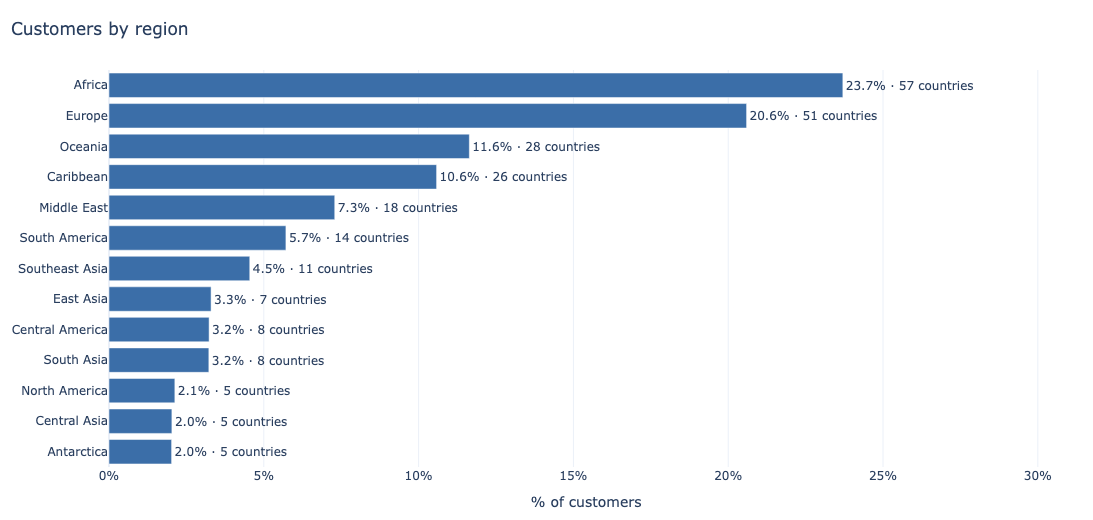

> Africa has the largest share (23.7%, 57 countries) and Antarctica the smallest (2.0%, 5 countries). Every region averages 403–471 customers per country, so a region's share mostly reflects how many countries it contains rather than stronger demand.

In [9]:
# Get Region Dataset
region = df.groupby("Region").agg(customers=("Country", "size"), countries=("Country", "nunique"))
region["pct"] = pct(region["customers"])
region["per_country"] = region["customers"] / region["countries"]
region = region.sort_values("customers")

fig = go.Figure(
    go.Bar(
        x=region["pct"],
        y=region.index,
        orientation="h",
        marker_color=COLOR,
        text=[f"{p:.1f}% · {c} countries" for p, c in zip(region["pct"], region["countries"])],
        textposition="outside",
        customdata=region[["customers", "countries", "per_country"]],
        hovertemplate=(
            "<b>%{y}</b><br>Customers: %{customdata[0]:,}<br>"
            "Countries: %{customdata[1]}<br>Per country: %{customdata[2]:.0f}<extra></extra>"
        ),
    )
)
fig.update_xaxes(title="% of customers", ticksuffix="%", range=[0, region["pct"].max() * 1.3])

top, bottom = region.iloc[-1], region.iloc[0]
note = (
    f"{top.name} has the largest share ({top.pct:.1f}%, {top.countries:.0f} countries) and "
    f"{bottom.name} the smallest ({bottom.pct:.1f}%, {bottom.countries:.0f} countries). "
    f"Every region averages {region['per_country'].min():.0f}–{region['per_country'].max():.0f} "
    "customers per country, so a region's share mostly reflects how many countries it contains "
    "rather than stronger demand."
)
show(styled(fig, "Customers by region", height=520), note)

#### **Countries with the most and fewest customers**

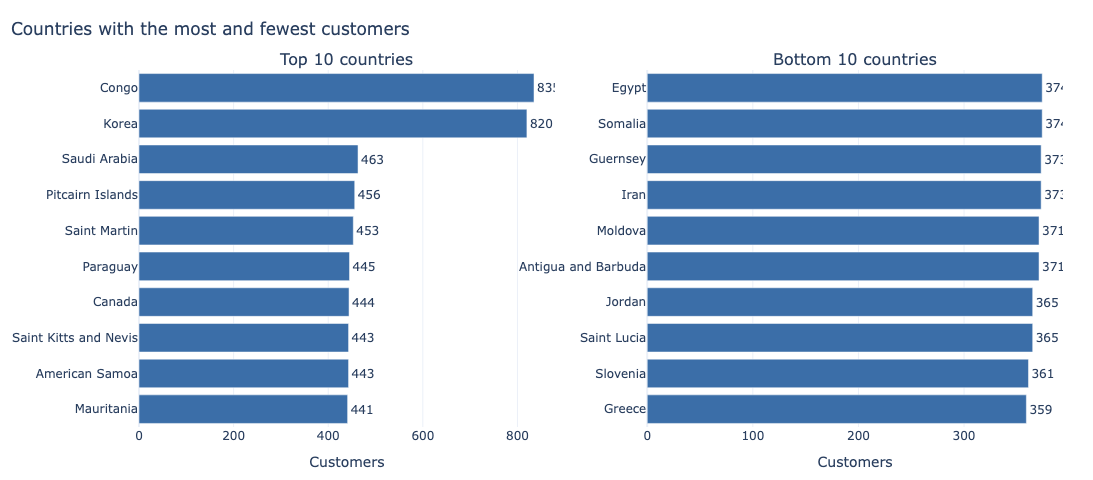

> Customers are spread across 243 countries, with a median of 409 per country. The largest is Congo (835) and the smallest Greece (359). Congo and Korea stand out because each label combines two countries (Congo covers Republic of the Congo and DR Congo; Korea covers North and South Korea). Excluding them, every country has between 359 and 463 customers.

In [10]:
n = 10
country = df["Country"].value_counts()

fig = make_subplots(rows=1, cols=2, subplot_titles=(f"Top {n} countries", f"Bottom {n} countries"))
for col, data in enumerate((country.head(n), country.tail(n)), start=1):
    data = data.sort_values()
    fig.add_trace(
        go.Bar(
            x=data.values, y=data.index, orientation="h",
            marker_color=COLOR, text=data.values, textposition="outside",
        ),
        row=1,
        col=col,
    )
fig.update_layout(showlegend=False)
fig.update_xaxes(title="Customers")

merged = [name for name in MERGED_NAMES if name in country.head(n).index]
rest = country.drop(merged)
note = (
    f"Customers are spread across {len(country)} countries, with a median of {country.median():.0f} per country. "
    f"The largest is {country.index[0]} ({country.iloc[0]:,}) and the smallest {country.index[-1]} "
    f"({country.iloc[-1]:,})."
)
if merged:
    detail = "; ".join(f"{name} covers {MERGED_NAMES[name]}" for name in merged)
    note += (
        f" {' and '.join(merged)} stand out because each label combines two countries ({detail}). "
        f"Excluding them, every country has between {rest.min():,} and {rest.max():,} customers."
    )
show(styled(fig, "Countries with the most and fewest customers", height=480), note)

#### **Regional share of subscriptions, by year**

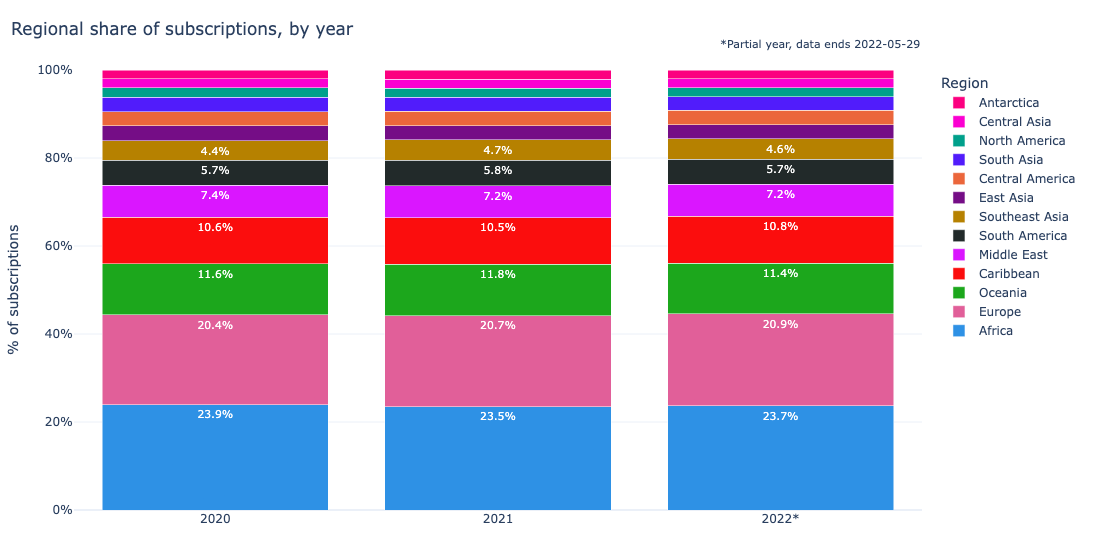

> Each bar splits one year's subscriptions by region. The regional mix barely changes between years: the largest shift is Europe at 0.52 percentage points (20.4% to 20.9%).

In [11]:
mix = pd.crosstab(date.dt.year, df["Region"], normalize="index") * 100
mix = mix[mix.mean().sort_values(ascending=False).index]
labels = [f"{y}*" if y == last.year else str(y) for y in mix.index]

fig = go.Figure(
    [
        go.Bar(
            name=name,
            x=labels,
            y=mix[name],
            text=mix[name].map("{:.1f}%".format),
            textposition="inside",
            hovertemplate=f"<b>{name}</b><br>%{{x}}: %{{y:.2f}}%<extra></extra>",
        )
        for name in mix.columns
    ]
)
fig.update_layout(
    barmode="stack",
    legend_title_text="Region",
    colorway=qualitative.Dark24,
    uniformtext=dict(minsize=9, mode="hide"),
)
fig.update_yaxes(title="% of subscriptions", ticksuffix="%", range=[0, 100])
partial_note(fig, f"*Partial year, data ends {last:%Y-%m-%d}")

shift = mix.max() - mix.min()
note = (
    "Each bar splits one year's subscriptions by region. The regional mix barely changes between years: "
    f"the largest shift is {shift.idxmax()} at {shift.max():.2f} percentage points "
    f"({mix[shift.idxmax()].min():.1f}% to {mix[shift.idxmax()].max():.1f}%)."
)
show(styled(fig, "Regional share of subscriptions, by year", height=560), note)

### **Subscriptions**
#### **Subscriptions per year**

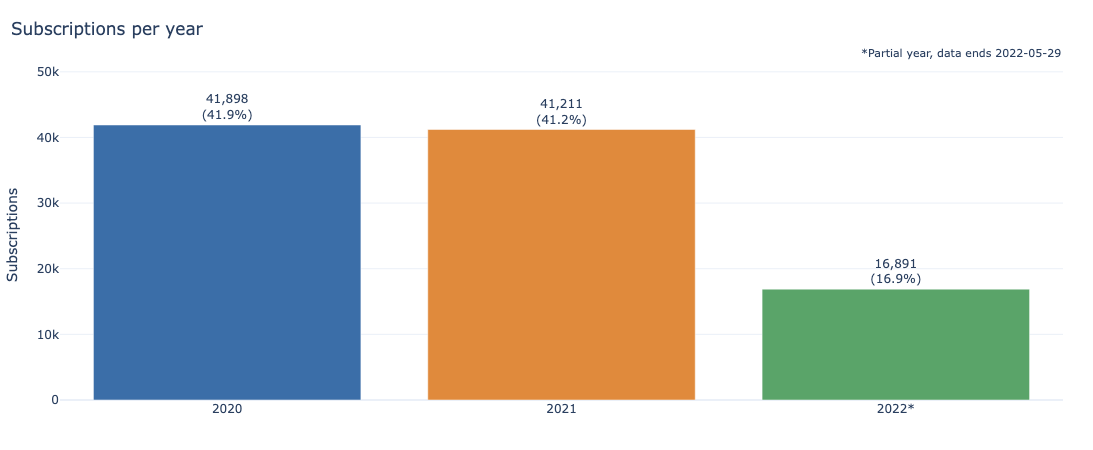

> Subscriptions run from 2020-01-01 to 2022-05-29. The full years are almost identical (2020: 41,898, 2021: 41,211). 2022 looks lower only because it covers 149 days; at the same daily rate it would reach about 41,377.

In [12]:
yearly = date.dt.year.value_counts().sort_index()
labels = [f"{y}*" if y == last.year else str(y) for y in yearly.index]

fig = go.Figure(
    go.Bar(
        x=labels,
        y=yearly.values,
        marker_color=[YEAR_COLORS.get(y, COLOR) for y in yearly.index],
        text=[f"{c:,}<br>({p:.1f}%)" for c, p in zip(yearly, pct(yearly))],
        textposition="outside",
    )
)
fig.update_yaxes(title="Subscriptions", range=[0, yearly.max() * 1.2])
partial_note(fig, f"*Partial year, data ends {last:%Y-%m-%d}")

full_years = yearly.drop(last.year)
days = (last - pd.Timestamp(year=last.year, month=1, day=1)).days + 1
pace = yearly[last.year] / days * 365
note = (
    f"Subscriptions run from {date.min():%Y-%m-%d} to {last:%Y-%m-%d}. "
    f"The full years are almost identical ({', '.join(f'{y}: {c:,}' for y, c in full_years.items())}). "
    f"{last.year} looks lower only because it covers {days} days; at the same daily rate "
    f"it would reach about {pace:,.0f}."
)
show(styled(fig, "Subscriptions per year"), note)

#### **Subscriptions per quarter, by year**

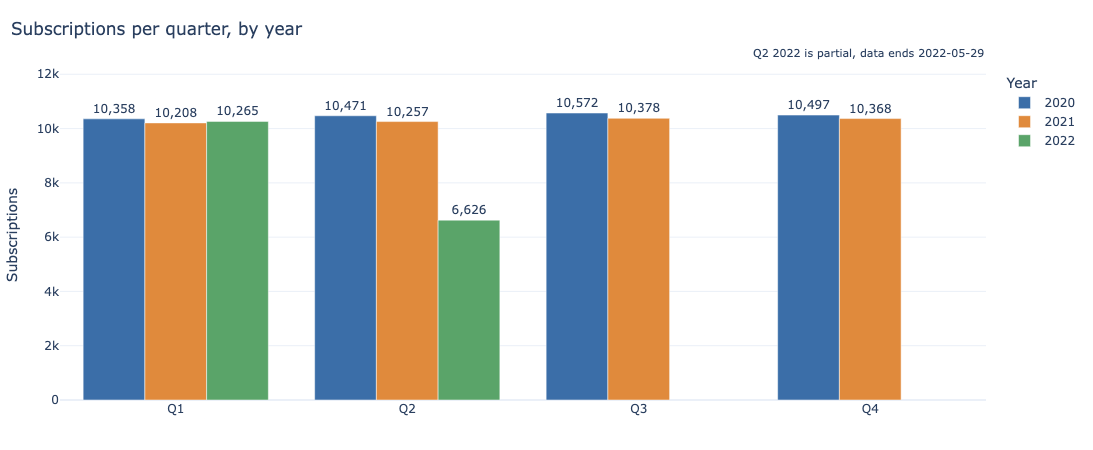

> Every complete quarter falls between 10,208 and 10,572 subscriptions, a spread of 3.5% around the mean of 10,375. Q2 2022 is short because the data stops on May 29.

In [13]:
quarterly = pd.crosstab(date.dt.quarter, date.dt.year).astype(float)
quarterly.loc[quarterly.index > last.quarter, last.year] = float("nan")

fig = go.Figure(
    [
        go.Bar(
            name=str(year),
            x=[f"Q{q}" for q in quarterly.index],
            y=quarterly[year],
            marker_color=YEAR_COLORS.get(year, COLOR),
            text=quarterly[year].map(lambda v: "" if pd.isna(v) else f"{v:,.0f}"),
            textposition="outside",
        )
        for year in quarterly.columns
    ]
)
fig.update_layout(barmode="group", legend_title_text="Year")
fig.update_yaxes(title="Subscriptions", range=[0, quarterly.max().max() * 1.15])
partial_note(fig, f"Q{last.quarter} {last.year} is partial, data ends {last:%Y-%m-%d}")

complete = quarterly.stack().drop((last.quarter, last.year))
note = (
    f"Every complete quarter falls between {complete.min():,.0f} and {complete.max():,.0f} subscriptions, "
    f"a spread of {(complete.max() - complete.min()) / complete.mean():.1%} around the mean of "
    f"{complete.mean():,.0f}. Q{last.quarter} {last.year} is short because the data stops on {last:%B %d}."
)
show(styled(fig, "Subscriptions per quarter, by year"), note)

#### **Subscriptions per month**

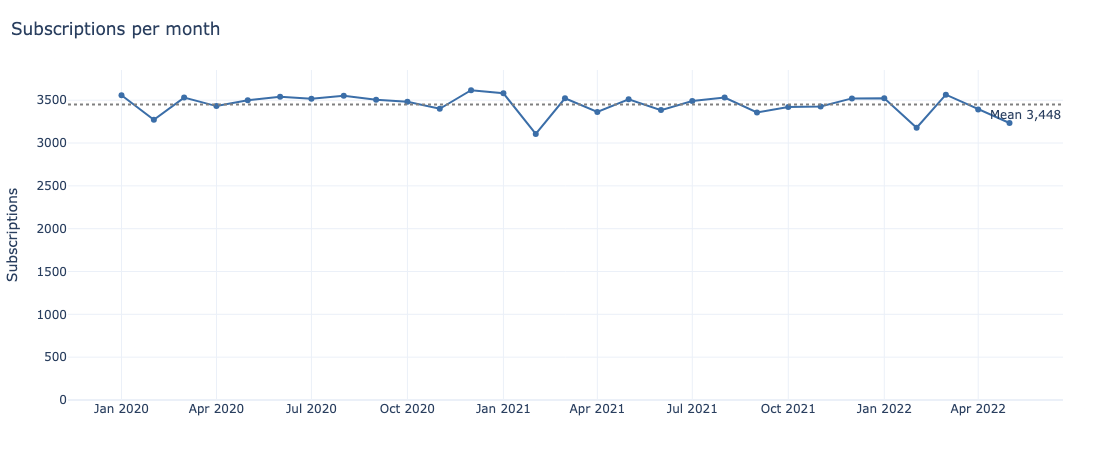

> Monthly subscriptions average 3,448. The highest month is Dec 2020 (3,616) and the lowest is Feb 2021 (3,106), which has fewer days. No month is more than 9.9% from the mean, so the line is flat with no growth trend.

In [14]:
monthly = date.dt.to_period("M").value_counts().sort_index()
mean = monthly.mean()

fig = go.Figure(
    go.Scatter(
        x=monthly.index.to_timestamp(), y=monthly.values,
        mode="lines+markers", line=dict(color=COLOR), name="Subscriptions",
    )
)
fig.add_hline(
    y=mean, line_dash="dot", line_color="gray",
    annotation_text=f"Mean {mean:,.0f}", annotation_position="bottom right",
)
fig.update_yaxes(title="Subscriptions", rangemode="tozero")
fig.update_xaxes(dtick="M3", tickformat="%b %Y")

low, high = monthly.idxmin(), monthly.idxmax()
note = (
    f"Monthly subscriptions average {mean:,.0f}. The highest month is {high:%b %Y} ({monthly[high]:,}) "
    f"and the lowest is {low:%b %Y} ({monthly[low]:,})"
    f"{', which has fewer days' if low.month == 2 else ''}. "
    f"No month is more than {(monthly - mean).abs().max() / mean:.1%} from the mean, so the line is "
    "flat with no growth trend."
)
show(styled(fig, "Subscriptions per month"), note)

#### **Subscriptions by weekday**

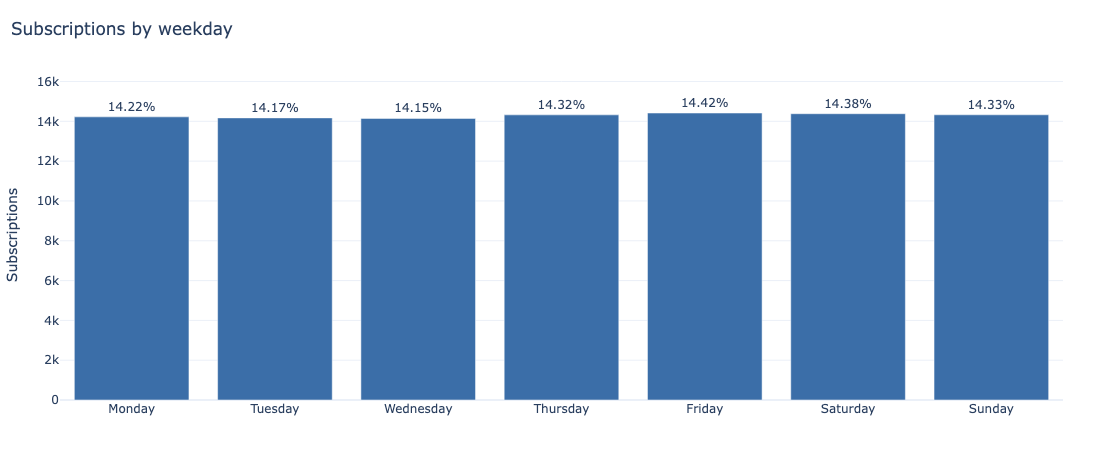

> An even split across 7 days would give 14.29% per day. The actual shares range from 14.15% (Wednesday) to 14.42% (Friday), so weekends and weekdays get essentially the same volume of sign-ups.

In [15]:
weekday = date.dt.day_name().value_counts().reindex(WEEKDAYS)
shares = pct(weekday)

fig = go.Figure(
    go.Bar(
        x=weekday.index,
        y=weekday.values,
        marker_color=COLOR,
        text=shares.map("{:.2f}%".format),
        textposition="outside",
    )
)
fig.update_yaxes(title="Subscriptions", range=[0, weekday.max() * 1.15])

note = (
    f"An even split across 7 days would give {100 / 7:.2f}% per day. The actual shares range from "
    f"{shares.min():.2f}% ({shares.idxmin()}) to {shares.max():.2f}% ({shares.idxmax()}), "
    "so weekends and weekdays get essentially the same volume of sign-ups."
)
show(styled(fig, "Subscriptions by weekday"), note)